# 04 — Experimentos

**Práctica 4 · Logística del Valle** (punto 7 del enunciado)

Repetimos la simulación en los tres escenarios de demanda y comparamos las dos políticas de rutas con
**los mismos pedidos** en cada pareja de ejecuciones. Después exploramos cómo cambian los resultados con el tamaño
de la flota y con la demanda, para identificar cuándo los vehículos se vuelven una limitación.

El código está en `src/experimentos.py`. Las tablas y figuras se guardan en `resultados/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import experimentos as e
from src import grafo as g
from src import simulacion as s
from src.graficas import COLOR_POLITICA

G = g.construir_grafo(g.cargar_matriz())
SALIDA = Path("resultados")
SALIDA.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

## 1. Diseño experimental

| Elemento | Valor |
|---|---|
| Escenarios | Normal (4 pedidos/h), Semana Santa (6), Navidad (10) |
| Repeticiones | **30 por escenario** (el enunciado pide al menos 5): semillas 1 a 30 |
| Flota | 8 vehículos |
| Recepción de pedidos | 8 horas; la simulación sigue hasta atender todos |
| Políticas | Actual vs. Recomendada (Dijkstra) |
| Control de variabilidad | **Números aleatorios comunes:** en cada semilla, ambas políticas reciben los mismos pedidos, en los mismos instantes y con los mismos destinos |

Usamos 30 repeticiones en lugar de 5 porque cada corrida tarda milisegundos y así los intervalos de confianza son
más estrechos.

**Métricas por corrida** (las que pide el enunciado):

- **Entregas puntuales:** pedidos entregados en ≤ 75 min desde la solicitud, incluida la espera (también en %).
- **Espera promedio:** tiempo en cola hasta que se asigna un vehículo.
- **Solicitud → entrega:** tiempo desde que llega el pedido hasta que se entrega.
- **Utilización:** tiempo ocupado de los vehículos / (vehículos × duración total de la operación).
- **Tiempo adicional:** minutos después del cierre de recepción (480 min) hasta entregar el último pedido.

**Análisis estadístico:** media de las 30 repeticiones con intervalo de confianza del 95 % (t de Student). Para comparar
políticas usamos la **diferencia pareada** por semilla (Recomendada − Actual) y una prueba t pareada.
Emparejar elimina la variación que viene de los pedidos y deja solo el efecto de las rutas.

In [2]:
REPETICIONES = 30
datos = e.correr(s.ESCENARIOS, repeticiones=REPETICIONES, vehiculos=8, horas=8, G=G)
datos.to_csv(SALIDA / "experimentos.csv", index=False)
print(f"{len(datos)} corridas ({len(s.ESCENARIOS)} escenarios × {REPETICIONES} semillas × 2 políticas)")
datos.head(6)

180 corridas (3 escenarios × 30 semillas × 2 políticas)


,escenario,pedidos por hora,vehículos,semilla,política,pedidos,entregas puntuales,puntualidad (%),espera promedio (min),espera máxima (min),solicitud→entrega promedio (min),solicitud→entrega máximo (min),utilización (%),tiempo adicional (min),fin de la operación (min)
0,Normal,4,8,1,Actual,28,17,60.7,7.8,53.3,63.6,108.5,61.9,57.7,630.7
1,Normal,4,8,1,Recomendada,28,28,100.0,1.1,14.7,33.4,65.7,46.9,11.7,552.7
2,Normal,4,8,2,Actual,35,29,82.9,3.8,37.6,55.2,101.2,70.1,67.8,640.8
3,Normal,4,8,2,Recomendada,35,35,100.0,0.1,1.9,31.5,51.0,56.8,13.6,554.6
4,Normal,4,8,3,Actual,36,17,47.2,19.7,72.8,77.6,158.2,72.9,141.8,714.8
5,Normal,4,8,3,Recomendada,36,36,100.0,0.6,15.2,34.5,51.0,59.4,45.8,586.8


## 2. Resultados por escenario y política

Media ± semiancho del intervalo de confianza del 95 %.

In [3]:
tabla_txt, tabla_num = e.resumen(datos)
tabla_txt.to_csv(SALIDA / "resumen_escenarios.csv")
tabla_txt

pedidos entregas puntuales puntualidad (%)  \
escenario    política                                                     
Normal       Actual       32.2 ± 1.9         17.4 ± 2.0      56.1 ± 7.5   
             Recomendada  32.2 ± 1.9         31.7 ± 1.8      98.7 ± 1.0   
Semana Santa Actual       48.7 ± 2.2         10.1 ± 1.8      21.2 ± 4.1   
             Recomendada  48.7 ± 2.2         38.7 ± 3.1      81.0 ± 7.1   
Navidad      Actual       80.0 ± 2.8          6.9 ± 0.7       8.7 ± 0.9   
             Recomendada  80.0 ± 2.8         15.2 ± 1.6      19.4 ± 2.3   

                         espera promedio (min)  \
escenario    política                            
Normal       Actual                 17.1 ± 5.8   
             Recomendada             2.1 ± 1.0   
Semana Santa Actual                83.8 ± 12.5   
             Recomendada            17.5 ± 5.1   
Navidad      Actual               290.2 ± 20.2   
             Recomendada          141.8 ± 13.3   

                         solicitud→entrega promedio (min) utilización (%)  \
escenario    política                                                       
Normal       Actual                            74.4 ± 6.3      71.8 ± 3.5   
             Recomendada                       37.6 ± 1.4      58.2 ± 3.2   
Semana Santa Actual                          140.2 ± 12.5      84.7 ± 1.6   
             Recomendada                       52.4 ± 5.1      80.0 ± 2.3   
Navidad      Actual                          346.7 ± 20.4      91.0 ± 0.9   
             Recomendada                     176.7 ± 13.3      90.9 ± 0.7   

                         tiempo adicional (min)  
escenario    política                            
Normal       Actual                 78.6 ± 16.9  
             Recomendada             23.5 ± 6.6  
Semana Santa Actual                242.9 ± 24.5  
             Recomendada            61.4 ± 10.6  
Navidad      Actual                672.4 ± 41.8  
             Recomendada           331.7 ± 27.2

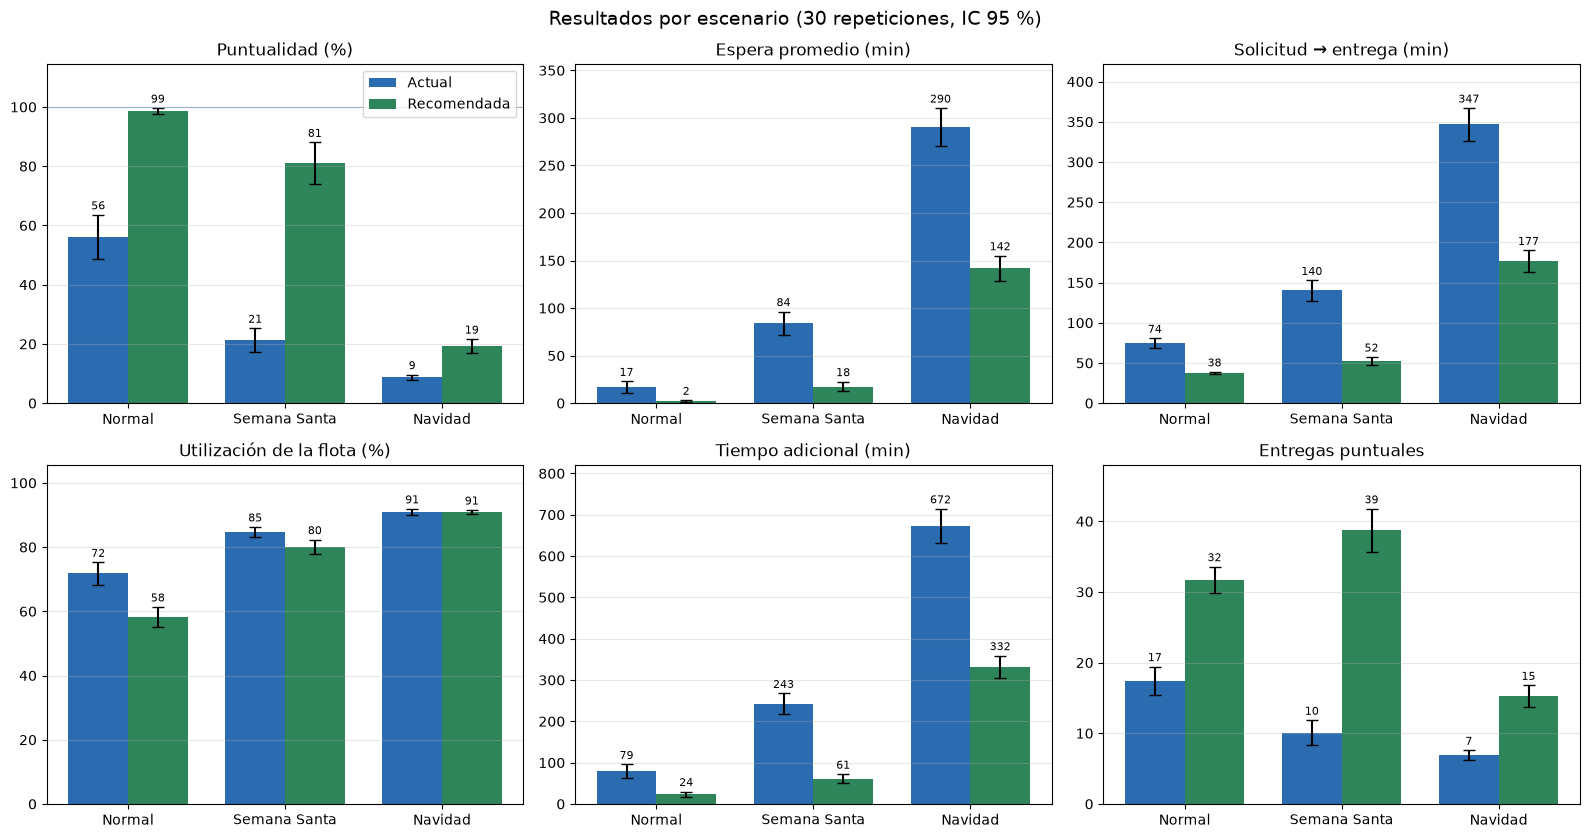

In [4]:
graficas = [
    ("puntualidad (%)", "Puntualidad (%)"),
    ("espera promedio (min)", "Espera promedio (min)"),
    ("solicitud→entrega promedio (min)", "Solicitud → entrega (min)"),
    ("utilización (%)", "Utilización de la flota (%)"),
    ("tiempo adicional (min)", "Tiempo adicional (min)"),
    ("entregas puntuales", "Entregas puntuales"),
]
escenarios = list(s.ESCENARIOS)
x = np.arange(len(escenarios))
ancho = 0.38

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, (metrica, titulo) in zip(axes.flat, graficas):
    for i, politica in enumerate(s.POLITICAS):
        medias = [tabla_num.loc[(esc, politica), metrica] for esc in escenarios]
        errores = [tabla_num.loc[(esc, politica), metrica + " ±"] for esc in escenarios]
        barras = ax.bar(x + (i - 0.5) * ancho, medias, ancho, yerr=errores, capsize=4,
                        color=COLOR_POLITICA[politica], label=politica)
        ax.bar_label(barras, fmt="%.0f", fontsize=8, padding=2)
    ax.set_xticks(x, escenarios)
    ax.set_title(titulo)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.15)
axes[0, 0].axhline(100, color="#a0aec0", lw=0.8)
axes[0, 0].legend(loc="upper right")
fig.suptitle(f"Resultados por escenario ({REPETICIONES} repeticiones, IC 95 %)", fontsize=14)
fig.tight_layout()
fig.savefig(SALIDA / "metricas_escenarios.png", dpi=130, bbox_inches="tight")
plt.show()

## 3. Efecto de cambiar las rutas (diferencias pareadas)

Recomendada − Actual, calculada semilla por semilla con los mismos pedidos. Un valor positivo en puntualidad y negativo
en tiempos significa que la política recomendada es mejor.

In [5]:
diferencias, p_valores = e.diferencias_pareadas(datos)
diferencias.to_csv(SALIDA / "diferencias_pareadas.csv")
diferencias

,entregas puntuales,puntualidad (%),espera promedio (min),solicitud→entrega promedio (min),utilización (%),tiempo adicional (min)
escenario,,,,,,
Normal,+14.3 ± 3.0,+42.5 ± 7.2,-15.0 ± 5.2,-36.8 ± 5.7,-13.6 ± 1.5,-55.1 ± 13.9
Semana Santa,+28.6 ± 3.0,+59.7 ± 6.3,-66.3 ± 8.4,-87.8 ± 8.6,-4.7 ± 1.5,-181.6 ± 17.2
Navidad,+8.3 ± 1.5,+10.6 ± 2.0,-148.4 ± 8.0,-170.0 ± 8.4,-0.2 ± 0.7,-340.7 ± 18.2


Valores p de la prueba t pareada (H₀: la diferencia media es cero):

In [6]:
p_valores.style.format("{:.2g}")

,entregas puntuales (p),puntualidad (%) (p),espera promedio (min) (p),solicitud→entrega promedio (min) (p),utilización (%) (p),tiempo adicional (min) (p)
escenario,,,,,,
Normal,1.3e-10,8.1e-13,2.1e-06,7.8e-14,5e-18,6.5e-09
Semana Santa,4e-18,4.6e-18,4.4e-16,4.9e-19,5.4e-07,2e-19
Navidad,2.1e-12,1.1e-11,2.7e-26,2.2e-27,0.63,2.3e-26


## 4. Puntualidad por destino

Agrupamos los pedidos de las 30 repeticiones por destino, para ver dónde se concentran los retrasos.

In [7]:
filas = []
for escenario, tasa in s.ESCENARIOS.items():
    for semilla in range(1, REPETICIONES + 1):
        _, res, _ = s.comparar(s.Parametros(pedidos_por_hora=tasa, semilla=semilla), G)
        for politica, rr in res.items():
            reg = rr["registros"]
            filas.append(reg.assign(escenario=escenario, política=politica,
                                    puntual=reg["solicitud_a_entrega"] <= 75))
pedidos_todos = pd.concat(filas, ignore_index=True)
por_destino = (pedidos_todos.groupby(["escenario", "política", "destino"], sort=False)["puntual"].mean()
               .mul(100).unstack("destino"))
por_destino.to_csv(SALIDA / "puntualidad_por_destino.csv")
por_destino.style.format("{:.0f} %")

## 5. ¿Cuándo la flota se vuelve una limitación?

### Tamaño de la flota

Repetimos los tres escenarios (30 semillas cada uno) con flotas de 4 a 20 vehículos.

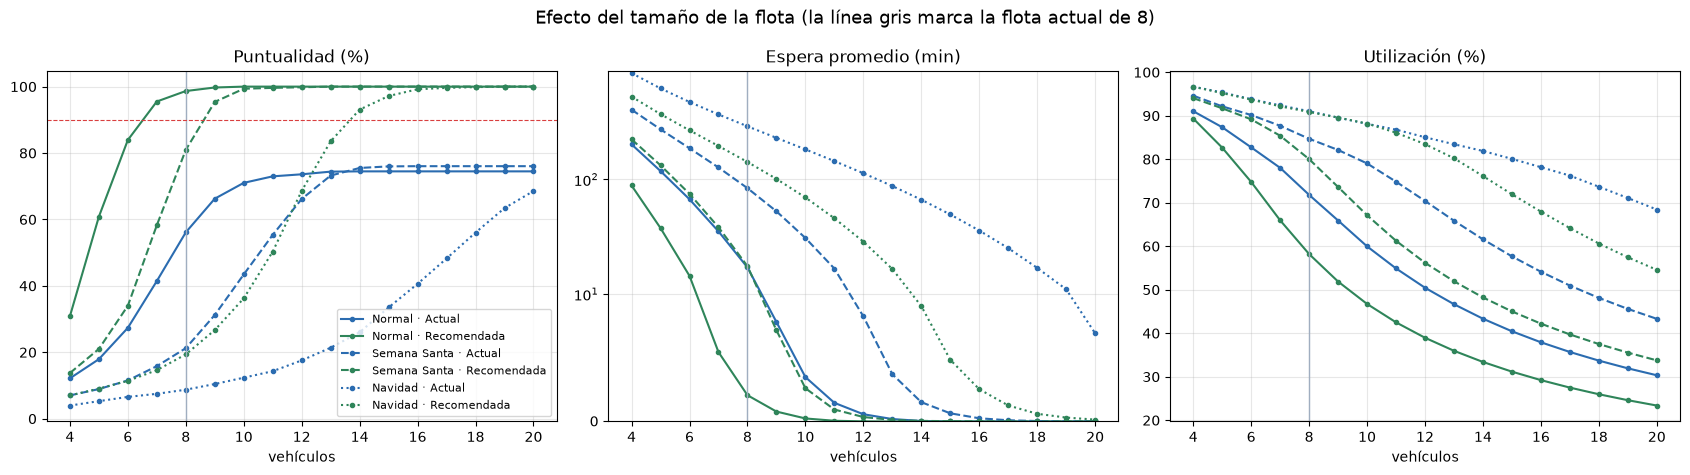

In [8]:
barrido_flota = e.barrido(tasas=list(s.ESCENARIOS.values()), vehiculos=range(4, 21), repeticiones=REPETICIONES, G=G)
barrido_flota.to_csv(SALIDA / "barrido_flota.csv", index=False)

nombres = {v: k for k, v in s.ESCENARIOS.items()}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (metrica, titulo) in zip(axes, [("puntualidad (%)", "Puntualidad (%)"),
                                        ("espera promedio (min)", "Espera promedio (min)"),
                                        ("utilización (%)", "Utilización (%)")]):
    for tasa, estilo in zip(s.ESCENARIOS.values(), ["-", "--", ":"]):
        for politica in s.POLITICAS:
            sub = barrido_flota[(barrido_flota["pedidos por hora"] == tasa) & (barrido_flota["política"] == politica)]
            ax.plot(sub["vehículos"], sub[metrica], estilo, marker="o", ms=3,
                    color=COLOR_POLITICA[politica], label=f"{nombres[tasa]} · {politica}")
    ax.axvline(8, color="#a0aec0", lw=1)
    ax.set_xlabel("vehículos")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
axes[0].axhline(90, color="#d93f3f", ls="--", lw=0.8)
axes[1].set_yscale("symlog", linthresh=10)
axes[1].set_ylim(bottom=0)
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Efecto del tamaño de la flota (la línea gris marca la flota actual de 8)", fontsize=13)
fig.tight_layout()
fig.savefig(SALIDA / "barrido_flota.png", dpi=130, bbox_inches="tight")
plt.show()

Flota mínima para alcanzar, en promedio, el 90 % y el 95 % de entregas puntuales:

In [9]:
minimos = pd.concat({
    f"≥ {objetivo} %": e.flota_minima(barrido_flota, objetivo=objetivo).reindex(columns=s.POLITICAS)
    for objetivo in (90, 95)
}, axis=1).rename(index=nombres).rename_axis("escenario")
maximo_actual = barrido_flota[barrido_flota["política"] == "Actual"].groupby("pedidos por hora")["puntualidad (%)"].max()
print("Puntualidad máxima de la política actual con 20 vehículos:",
      ", ".join(f"{nombres[t]} {v:.0f} %" for t, v in maximo_actual.items()))
minimos.to_csv(SALIDA / "flota_minima.csv")
minimos.fillna("nunca").astype(str).replace(r"\.0$", "", regex=True)

Puntualidad máxima de la política actual con 20 vehículos: Normal 74 %, Semana Santa 76 %, Navidad 69 %


≥ 90 %             ≥ 95 %            
política     Actual Recomendada Actual Recomendada
escenario                                         
Normal        nunca           7  nunca           7
Semana Santa  nunca           9  nunca           9
Navidad       nunca          14  nunca          15

### Demanda

Con la flota actual de 8 vehículos, variamos los pedidos por hora de 2 a 14.

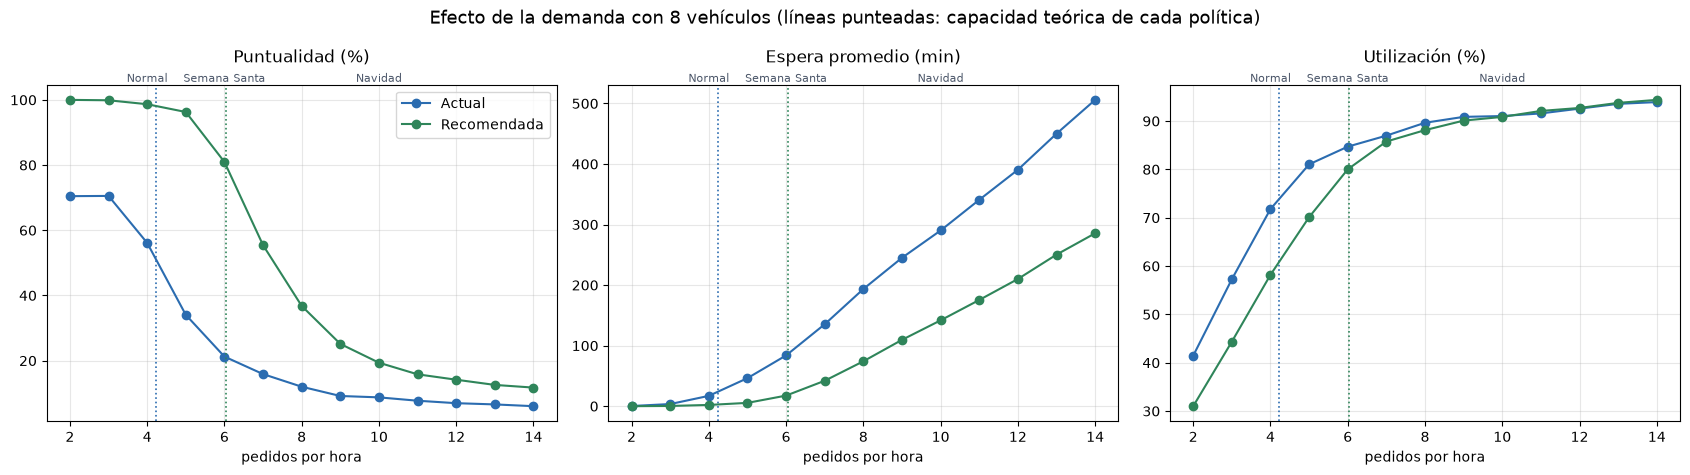

In [10]:
barrido_demanda = e.barrido(tasas=list(range(2, 15)), vehiculos=[8], repeticiones=REPETICIONES, G=G)
barrido_demanda.to_csv(SALIDA / "barrido_demanda.csv", index=False)

capacidad = {"Actual": 8 * 60 / 113.5, "Recomendada": 8 * 60 / 79.5}  # pedidos/h que la flota puede atender
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (metrica, titulo) in zip(axes, [("puntualidad (%)", "Puntualidad (%)"),
                                        ("espera promedio (min)", "Espera promedio (min)"),
                                        ("utilización (%)", "Utilización (%)")]):
    for politica in s.POLITICAS:
        sub = barrido_demanda[barrido_demanda["política"] == politica]
        ax.plot(sub["pedidos por hora"], sub[metrica], marker="o", color=COLOR_POLITICA[politica], label=politica)
        ax.axvline(capacidad[politica], color=COLOR_POLITICA[politica], ls=":", lw=1.2)
    for tasa, nombre in nombres.items():
        ax.text(tasa, ax.get_ylim()[1], nombre, fontsize=8, ha="center", va="bottom", color="#4a5568")
    ax.set_xlabel("pedidos por hora")
    ax.set_title(titulo, pad=16)
    ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle("Efecto de la demanda con 8 vehículos (líneas punteadas: capacidad teórica de cada política)", fontsize=13)
fig.tight_layout()
fig.savefig(SALIDA / "barrido_demanda.png", dpi=130, bbox_inches="tight")
plt.show()

La **capacidad teórica** de la flota es el número de pedidos por hora que puede atender si nunca está ociosa:
8 vehículos × 60 / ciclo promedio. Con las rutas actuales (ciclo promedio 113.5 min) son **4.2 pedidos/h**; con las
recomendadas (79.5 min), **6.0 pedidos/h**. Cuando la demanda se acerca a ese valor, la espera se dispara.

## Conclusiones de los experimentos

Ver la sección **Resultados** del README para el resumen con las cifras finales.